# 62. Coarse-rotation specialist: frozen Transformer vs full fine-tuning

**Purpose:** isolate whether large-angle specialization requires adapting the Transformer or whether the existing `002.30` Transformer features are already sufficient for a **separate pooler + MLP + 6D head**.

Two matched stochastic runs start from the **identical complete `002.30/best.pt` checkpoint** and see the exact same training cases, with one randomly faulted sensor and 120°–179° corrections about either a Cartesian or arbitrary axis. The only controlled difference is which parameters can change:

- **`full`:** Transformer + pooler + shared MLP + 6D head.
- **`freeze_transformer`:** Transformer frozen; pooler + shared MLP + 6D head learn.

The stochastic experiments are **independent** and do not modify the main model. Then choose `FULL_TRAIN_MODE` and start or resume a full run in a **mode-specific directory**. Checkpoint selection uses a *coarse-only*, balanced sensor/axis validation score. Small-angle probes and zero-fault drift are reported separately as diagnostics.

**Interpretation:** successful frozen-Transformer training would support sharing a single pretrained Transformer with separate downstream fine and coarse branches. It would not automatically give an inference-time handoff rule; that requires its own confidence/stability criterion. Original Notebook 61, 002.30, and all prior checkpoints remain untouched.

## 1. Imports and project environment

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
from collections import defaultdict
import copy
import json
import gc
import math
import random
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Run from the nn-obs-calib repository or a descendant directory.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.geometry.rotation_6d import matrix_to_rotation_6d, rotation_6d_to_matrix
from obscalib.models.pooled_calibration_6d_model import PooledCalibration6DModel, load_6d_pretrained_features
from obscalib.calibration.rotation_6d_update import apply_calibration_6d_update
from obscalib.training.rotation_6d_loss import Calibration6DLossWeights, calibration_6d_loss
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint

print('Repository:', ROOT, '| Torch:', torch.__version__, '| CUDA:', torch.cuda.is_available())

Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | Torch: 2.7.1+cu126 | CUDA: True


## 2. Settings and controlled comparison

In [19]:
RUN_NAME = 'kaist_pooled_calibration_6d_002.33_coarse_specialist'
SOURCE_230_PATH = ROOT / 'runs' / 'kaist_pooled_calibration_6d_002.30_all_sensors_single_axis_xyz' / 'best.pt'
SOURCE_227_PATH = ROOT / 'runs' / 'kaist_pooled_calibration_6d_002.27_full_rotation_regression' / 'best.pt'
RUN_DIR = ROOT / 'runs' / RUN_NAME

RANDOM_SEED, TRAIN_AUG_SEED, VAL_AUG_SEED = 12345, 23456, 34567
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DTYPE = torch.float32
CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')
WINDOW_DURATION_S, WINDOW_STRIDE_S, MAX_SAMPLES_PER_SENSOR = 5.0, 5.0, 700
MEASUREMENT_DIM, TOKEN_INPUT_DIM = 6, 8
D_MODEL, N_HEADS, NUM_TRANSFORMER_LAYERS, DIM_FEEDFORWARD = 128, 8, 12, 512
TRANSFORMER_DROPOUT, NUM_SUMMARY_TOKENS = 0.0, 1
POOLER_N_HEADS, POOLER_DROPOUT = 8, 0.0
MLP_HIDDEN_DIMS, SHARED_FEATURE_DIM, MLP_DROPOUT = (256, 128), 128, 0.0
HEAD_HIDDEN_DIMS, HEAD_DROPOUT = (128, 64), 0.0
REFINED_TAU_BY_SENSOR_S = {'imu': 0.0, 'lidar': -0.025, 'lidar_right': -0.035}
KAIST_TAU_IMU_S, KAIST_TAU_LIDAR_S, KAIST_TAU_LIDAR_RIGHT_S = 0.0, -0.025, -0.035
RANDOMIZE_TRUE_SENSOR_FRAMES = True
TRUE_CALIBRATION_ROTATION_MAX_RAD = np.deg2rad(180.0)

# Coarse-only target. Change min to 90° if 120–179° under-trains the transition region.
COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG = 90.0, 179.0
COARSE_CARTESIAN_PROBABILITY = 0.00
COARSE_IDENTITY_PROBABILITY = 0.00
ACTIVE_ROTATION_SUPERVISION_WEIGHT = 0.75
LOSS_WEIGHTS = Calibration6DLossWeights(
    rotation_weight=2.0, rotation_6d_weight=1.0, rotation_chordal_weight=0.0,
    translation_weight=0.0, time_offset_weight=0.0,
    translation_scale_m=0.05, time_offset_scale_s=0.05,
)
STOCHASTIC_MODES = ('full', 'freeze_transformer')

# Full training: choose after comparing stochastic validation curves.
RUN_FULL_TRAINING = True
RESUME_FULL_TRAINING = False
FULL_TRAIN_MODE = 'freeze_transformer'  # 'full' or 'freeze_transformer'
FULL_INIT_MODE = 'source'              # 'source' or 'stochastic_best' (new optimizer in either case)
FULL_TARGET_EPOCHS = 40               # TOTAL epochs when resuming
TRAIN_BATCH_SIZE, NUM_WORKERS, GRADIENT_ACCUMULATION_STEPS = 32, 0, 1
HEAD_MLP_LR, TRANSFORMER_LR = 5e-5, 5e-6
WEIGHT_DECAY, GRADIENT_CLIP_NORM = 1e-4, 1.0
LR_REDUCE_FACTOR, LR_PATIENCE_PROBES = 0.5, 8
PROBE_EVERY_EPOCHS = 1
MAX_TRAIN_BATCHES_PER_EPOCH, MAX_VAL_BATCHES_PER_EPOCH = None, None

# Paired validation: the same fixed cases are used for every model/optimizer mode.
PROBE_ANGLES_DEG = (0.0, 30.0, 60.0, 90.0, 120.0, 150.0, 175.0, 179.0)
PROBE_SCORE_ANGLES_DEG = (120.0, 150.0, 175.0, 179.0)
PROBE_CARTESIAN_SCORE_WEIGHT = 0.50
PROBE_SEED = VAL_AUG_SEED + 6_200_100
FULL_PROBE_WINDOWS, FULL_PROBE_BATCH_SIZE, FULL_PROBE_3D_DIRECTIONS = 16, 8, 3
WORST_PAIR_WEIGHT, NEAR_PI_WEIGHT, ZERO_DRIFT_WEIGHT = 0.25, 0.10, 0.0
SHOW_PLOTS = True

RUN_POST_EVAL = False
EVAL_WINDOWS, EVAL_BATCH_SIZE, EVAL_3D_DIRECTIONS = 32, 8, 3
EVAL_INCLUDE_STOCHASTIC_MODELS = True
EVAL_ROLLOUTS = False
EVAL_ROLLOUT_SEQUENCES = ('Urban26', 'Urban28')
EVAL_ROLLOUT_STARTS, EVAL_ROLLOUT_TRUTHS, EVAL_ROLLOUT_STEPS = 1, 1, 12
EVAL_ROLLOUT_ANGLES = (30.0, 90.0, 150.0, 179.0)
EVAL_ROLLOUT_3D_DIRECTIONS = 2

assert SOURCE_230_PATH.is_file(), f'Complete 002.30 checkpoint missing: {SOURCE_230_PATH}'
assert 0.0 < COARSE_ROTATION_MIN_DEG < COARSE_ROTATION_MAX_DEG < 180.0
assert 0 <= COARSE_CARTESIAN_PROBABILITY <= 1
assert 0 <= COARSE_IDENTITY_PROBABILITY < 1
# assert FULL_TRAIN_MODE in STOCHASTIC_MODES and FULL_INIT_MODE in ('source', 'stochastic_best')
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if DEVICE.type == 'cuda':
    torch.cuda.manual_seed_all(RANDOM_SEED)
RUN_DIR.mkdir(parents=True, exist_ok=True)
print('Notebook 62:', RUN_DIR)
print('Initializing ENTIRE architecture from', SOURCE_230_PATH)
print('Coarse 120–179°; full / frozen-Transformer comparison, with unchanged 6D objective')

Notebook 62: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.33_coarse_specialist
Initializing ENTIRE architecture from /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.30_all_sensors_single_axis_xyz/best.pt
Coarse 120–179°; full / frozen-Transformer comparison, with unchanged 6D objective


## 3. Dataset and existing KAIST calibration conventions

In [5]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")

TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES

if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError("Train, validation, and test sequence sets overlap.")

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

# Right LiDAR -> body, in the same convention as T_B_L for the left LiDAR.
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=float)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=KAIST_TAU_IMU_S, tau_lidar_s=KAIST_TAU_LIDAR_S, T_B_L_right=T_B_L_right, tau_lidar_right_s=KAIST_TAU_LIDAR_RIGHT_S)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)

print("train:", TRAIN_NAMES)
print("validation:", VAL_NAMES)
print("test:", TEST_NAMES)
print("Corrected rig τ [ms]:", {key: 1000.0 * value for key, value in REFINED_TAU_BY_SENSOR_S.items()})


train: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
validation: ['Urban26', 'Urban28']
test: ['Urban38', 'Urban39']
Corrected rig τ [ms]: {'imu': 0.0, 'lidar': -25.0, 'lidar_right': -35.0}


In [6]:
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")

# The 3-sensor experiment must never silently fall back to 2 sensors.
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Missing required right-LiDAR pose CSV for {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

train_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TRAIN_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
val_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in VAL_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
test_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TEST_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

for split_name, dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(dataset.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"{split_name} dataset has calibration keys {dataset.calibration_keys}, expected {CALIBRATION_KEYS}")

print(train_dataset.summary())
print()
print(val_dataset.summary())
print()
print(test_dataset.summary())

# Check the actual WindowBatch ground truth, not just constructor arguments.
for split_name, split_dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    sample = collate_windows([split_dataset[0]])
    for sensor, expected_s in REFINED_TAU_BY_SENSOR_S.items():
        observed = float(sample.current_calibration[sensor].time_offset.reshape(-1)[0].item())
        assert abs(observed - expected_s) < 2e-6, f"{split_name}/{sensor}: dataset τ={observed} but expected {expected_s}"
    print(f"{split_name}: τ targets [ms] verified:", {sensor: round(float(state.time_offset.reshape(-1)[0]) * 1000, 3) for sensor, state in sample.current_calibration.items()})

# Compare the zero-clock and corrected-clock dataset instances on the same held-out
# physical windows. This checks whether the loader alters raw measurements when the
# rig reference changes; it never deliberately shifts raw timestamps in this notebook.
zero_clock_rig = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
zero_clock_control = KAISTCalibrationDataset([spec_by_name[TEST_NAMES[0]]], zero_clock_rig, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
corrected_control = KAISTCalibrationDataset([spec_by_name[TEST_NAMES[0]]], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
if len(zero_clock_control) != len(corrected_control):
    raise RuntimeError("Changing calibration τ modified the number of windows. Inspect dataset timestamp processing before training.")
for index in sorted({0, len(zero_clock_control)//2, len(zero_clock_control)-1}):
    old, new = zero_clock_control[index], corrected_control[index]
    for stream_name in old.streams:
        old_stream, new_stream = old.streams[stream_name], new.streams[stream_name]
        torch.testing.assert_close(old_stream.values, new_stream.values, rtol=0, atol=0)
        torch.testing.assert_close(old_stream.timestamps, new_stream.timestamps, rtol=0, atol=0)
        if old_stream.interval_start_timestamps is not None:
            torch.testing.assert_close(old_stream.interval_start_timestamps, new_stream.interval_start_timestamps, rtol=0, atol=0)
print("PASS: refined τ changes calibration reference while preserving native stream measurements and timestamps.")
del zero_clock_control, corrected_control


KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704

KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658

KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiD

In [7]:
train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=TRAIN_BATCH_SIZE, shuffle=True, drop_last=True, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=TRAIN_BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)
print('Train/validation windows:', len(train_dataset), len(val_dataset))
print('Batches:', len(train_loader), len(val_loader))


Train/validation windows: 2006 418
Batches: 62 14


## 4. Physical augmentation, model, and original 6D objective

In [8]:
true_calibration_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False),
    true_calibration=TrueCalibrationAugmentationConfig(enabled=RANDOMIZE_TRUE_SENSOR_FRAMES, probability=1.0, rotation_probability=1.0, translation_probability=0.0, time_offset_probability=0.0, rotation=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_ROTATION_MAX_RAD)),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)
physical_augmenter = AugmentationPipeline(true_calibration_config)

def augmentation_generator(seed):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))

def clone_with_current_calibration(window, states):
    return WindowBatch(streams=dict(window.streams), current_calibration=states, metadata=dict(window.metadata), targets=window.targets, dataset_indices=window.dataset_indices)

def apply_independent_prior_faults(states, xi_by_key):
    """Left-multiply rotation ONLY, leaving lever arms, time offsets and healthy sensors untouched."""
    updated = {}
    for key, state in states.items():
        prior = state.transform.clone()
        prior[:, :3, :3] = so3_exp(xi_by_key[key][:, :3]) @ state.transform[:, :3, :3]
        updated[key] = replace(state, transform=prior)
    return updated

print('Physical augmentation matches Notebook 60: randomized true frames, no artificial sensor noise.')


Physical augmentation matches Notebook 60: randomized true frames, no artificial sensor noise.


In [9]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation='gelu'),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation='gelu', dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(n_heads=POOLER_N_HEADS, dropout=POOLER_DROPOUT, calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=HEAD_HIDDEN_DIMS, activation='gelu', dropout=HEAD_DROPOUT),
)
geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)
model = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=DTYPE)
load_training_checkpoint(SOURCE_230_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
model.freeze_feature_extractor(False)
model.head_6d.requires_grad_(True)
assert all(p.requires_grad for p in model.parameters())

def model_predictions(window, *, model_override=None):
    if tuple(window.current_calibration) != CALIBRATION_KEYS:
        raise ValueError(f'Unexpected key order: {tuple(window.current_calibration)}')
    canonical = geometry_processor(window.streams, window.metadata, window.current_calibration)
    tokens = tokenizer(canonical, calibration_keys=tuple(window.current_calibration))
    return (model if model_override is None else model_override)(tokens)

def parameter_groups(module, *, transformer_lr=TRANSFORMER_LR, other_lr=HEAD_MLP_LR):
    transformer = list(module.transformer_encoder.parameters())
    other = list(module.pooler.parameters()) + list(module.mlp_body.parameters()) + list(module.head_6d.parameters())
    assert len({id(p) for p in transformer + other}) == len(list(module.parameters()))
    return [dict(params=transformer, lr=transformer_lr, name='transformer'), dict(params=other, lr=other_lr, name='pooler_mlp_head')]

print('Loaded COMPLETE 002.30 model, including 6D head. Parameters:', sum(p.numel() for p in model.parameters()))


Loaded COMPLETE 002.30 model, including 6D head. Parameters: 2554570


In [10]:
def rotation_geodesic_deg(R_first, R_second):
    """Numerically stable geodesic SO(3) angle, including near 180°. Shape [...]."""
    relative = R_first @ R_second.transpose(-1, -2)
    skew = torch.stack((relative[..., 2, 1] - relative[..., 1, 2], relative[..., 0, 2] - relative[..., 2, 0], relative[..., 1, 0] - relative[..., 0, 1]), dim=-1)
    sine = 0.5 * torch.linalg.vector_norm(skew, dim=-1)
    cosine = 0.5 * (relative.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1.0)
    return torch.rad2deg(torch.atan2(sine, cosine))


def compute_6d_objective(window, output):
    """Joint 6D+chordal rotation loss, translation/tau loss, and active-fault emphasis."""
    if window.targets is None:
        raise ValueError('Training requires full GT targets')
    supervised = calibration_6d_loss(output.predictions, window.current_calibration, window.targets, weights=LOSS_WEIGHTS)
    active_terms, active_angle_errors, active_predicted_angles, active_target_angles = [], [], [], []
    for key in CALIBRATION_KEYS:
        state, truth, pred = window.current_calibration[key], window.targets[key], output.predictions[key]
        R_target = truth.next_transform[:, :3, :3] @ state.transform[:, :3, :3].transpose(-1, -2)
        angle_before = rotation_geodesic_deg(state.transform[:, :3, :3], truth.next_transform[:, :3, :3])
        active = angle_before > 1e-3
        if bool(active.any()):
            target_6d = matrix_to_rotation_6d(R_target)
            reg = (pred.rotation_6d - target_6d).square().mean(dim=-1)
            chord = 0.5 * (pred.delta_rotation - R_target).square().sum(dim=(-2, -1))
            active_terms.append((LOSS_WEIGHTS.rotation_6d_weight * reg + LOSS_WEIGHTS.rotation_chordal_weight * chord)[active])
            active_angle_errors.append(rotation_geodesic_deg(pred.delta_rotation[active], R_target[active]).detach())
            active_predicted_angles.append(rotation_geodesic_deg(pred.delta_rotation[active], torch.eye(3, device=DEVICE, dtype=DTYPE).expand_as(pred.delta_rotation[active])).detach())
            active_target_angles.append(angle_before[active].detach())
    extra_active = LOSS_WEIGHTS.rotation_weight * torch.cat(active_terms).mean() if active_terms else supervised.total * 0.0
    loss = supervised.total + ACTIVE_ROTATION_SUPERVISION_WEIGHT * extra_active
    with torch.no_grad():
        corrected = apply_calibration_6d_update(window.current_calibration, output.predictions)
        values = {}
        for key in CALIBRATION_KEYS:
            target = window.targets[key]
            state = corrected[key]
            values[f'{key}/rotation_error_deg'] = rotation_geodesic_deg(state.transform[:, :3, :3], target.next_transform[:, :3, :3]).mean().item()
            values[f'{key}/translation_error_cm'] = (100.0 * torch.linalg.vector_norm(state.transform[:, :3, 3] - target.next_transform[:, :3, 3], dim=-1)).mean().item()
            values[f'{key}/tau_error_ms'] = (1000.0 * (state.time_offset - target.next_time_offset).abs()).mean().item()
        values.update({'loss_total': float(loss.detach()), 'loss_supervised': float(supervised.total.detach()), 'loss_active_rotation': float(extra_active.detach()), 'loss_rotation_6d': float(supervised.rotation_6d.detach()), 'loss_rotation_chordal': float(supervised.rotation_chordal.detach()), 'loss_translation': float(supervised.translation.detach()), 'loss_tau': float(supervised.time_offset.detach()), 'active_rotation_error_deg': torch.cat(active_angle_errors).mean().item() if active_angle_errors else 0.0, 'active_target_deg': torch.cat(active_target_angles).mean().item() if active_target_angles else 0.0, 'active_predicted_step_deg': torch.cat(active_predicted_angles).mean().item() if active_predicted_angles else 0.0, 'active_rotation_count': sum(x.numel() for x in active_angle_errors)})
    return loss, values


def metric_average(sums, counts):
    return {key: sums[key] / counts[key] for key in sums}


## 5. Coarse-only fault sampler and trainable parameter modes

In [20]:
def coarse_prior_config_62(*, arbitrary):
    magnitude = PerturbationMagnitudeConfig(
        minimum=np.deg2rad(COARSE_ROTATION_MIN_DEG),
        maximum=np.deg2rad(COARSE_ROTATION_MAX_DEG),
        distribution=PerturbationDistribution.UNIFORM,
    )
    return PriorPerturbationConfig(
        enabled=True, probability=1.0, probability_by_key={}, rotation=magnitude,
        translation=None, time_offset=None, one_calibration_per_sample=True,
        one_rotation_axis_per_sample=not arbitrary, rotation_axes=(True, True, True),
        one_perturbation_type_per_sample=False,
    )

coarse_samplers_62 = {
    'cartesian': CalibrationPriorPerturber(coarse_prior_config_62(arbitrary=False)),
    'arbitrary': CalibrationPriorPerturber(coarse_prior_config_62(arbitrary=True)),
}

@torch.no_grad()
def sample_coarse_window_62(base, *, generator, physical_window=None, return_info=False):
    """Sample exactly one faulted sensor, either a Cartesian or uniform 3D axis, 120–179°.

    The identity branch is an explicit 10% control, not a small-angle training branch.
    """
    physical = physical_augmenter(base, generator=generator).augmented_window if physical_window is None else physical_window
    truth = physical.current_calibration
    n = next(iter(truth.values())).transform.shape[0]
    cart_xi = coarse_samplers_62['cartesian'](truth, generator=generator)[1]
    arb_xi = coarse_samplers_62['arbitrary'](truth, generator=generator)[1]
    cartesian_mask = torch.rand(n, device=DEVICE, generator=generator) < COARSE_CARTESIAN_PROBABILITY
    identity_mask = torch.rand(n, device=DEVICE, generator=generator) < COARSE_IDENTITY_PROBABILITY
    xi = {key: torch.where(cartesian_mask[:, None], cart_xi[key], arb_xi[key]).masked_fill(identity_mask[:, None], 0.0) for key in CALIBRATION_KEYS}
    rotations = torch.stack([xi[key][:, :3] for key in CALIBRATION_KEYS], dim=1)
    active = torch.linalg.vector_norm(rotations, dim=-1) > 1e-8
    angles = torch.rad2deg(torch.linalg.vector_norm(rotations, dim=-1).sum(dim=-1))
    assert bool((active.sum(dim=1) <= 1).all()), 'Sampler perturbed more than one sensor'
    assert bool(((angles[~identity_mask] >= COARSE_ROTATION_MIN_DEG - 0.1) & (angles[~identity_mask] <= COARSE_ROTATION_MAX_DEG + 0.1)).all()), 'Coarse rotation outside specified range'
    assert bool(((rotations[cartesian_mask & ~identity_mask].abs() > 1e-8).sum(dim=(1, 2)) <= 1).all()), 'Non-Cartesian fault in the Cartesian branch'
    assert all(bool((xi[key][:, 3:] == 0).all()) for key in CALIBRATION_KEYS)
    window = clone_with_current_calibration(physical, apply_independent_prior_faults(truth, xi))
    if return_info:
        return window, dict(cartesian=cartesian_mask.cpu().numpy(), identity=identity_mask.cpu().numpy(), active=active.cpu().numpy(), angles=angles.cpu().numpy())
    return window


def load_62_model():
    candidate = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=DTYPE)
    load_training_checkpoint(SOURCE_230_PATH, model=candidate, map_location=DEVICE, restore_rng_state=False)
    return candidate


def set_62_train_mode(candidate, mode):
    """No layer is reinitialized. Frozen mode trains pooler+MLP+6D head, never Transformer."""
    if mode not in STOCHASTIC_MODES:
        raise ValueError(mode)
    candidate.transformer_encoder.requires_grad_(mode == 'full')
    for module in (candidate.pooler, candidate.mlp_body, candidate.head_6d):
        module.requires_grad_(True)
    return candidate


def trainable_parameter_groups_62(candidate, *, transformer_lr, other_lr):
    transformer = list(candidate.transformer_encoder.parameters())
    downstream = list(candidate.pooler.parameters()) + list(candidate.mlp_body.parameters()) + list(candidate.head_6d.parameters())
    assert len({id(p) for p in transformer + downstream}) == len(list(candidate.parameters()))
    assert all(p.requires_grad for p in downstream)
    return [dict(params=transformer, lr=transformer_lr, name='transformer'), dict(params=downstream, lr=other_lr, name='pooler_mlp_head')]


def train_mode_checks_62(candidate, mode):
    transformer = list(candidate.transformer_encoder.parameters())
    downstream = list(candidate.pooler.parameters()) + list(candidate.mlp_body.parameters()) + list(candidate.head_6d.parameters())
    assert all(p.requires_grad == (mode == 'full') for p in transformer)
    assert all(p.requires_grad for p in downstream)
    return dict(mode=mode, transformer_trainable=sum(p.numel() for p in transformer if p.requires_grad), downstream_trainable=sum(p.numel() for p in downstream if p.requires_grad))


def transformer_weight_change_62(candidate, reference):
    return math.sqrt(sum(float((p.detach() - q.detach()).square().sum()) for p, q in zip(candidate.transformer_encoder.parameters(), reference.transformer_encoder.parameters())))

# Check geometry, sensor selection, actual magnitude distribution and frozen behavior.
smoke_base = window_batch_to(collate_windows([train_dataset[i] for i in np.linspace(0, len(train_dataset)-1, 16).astype(int)]), DEVICE, dtype=DTYPE)
info_rows = []
for j in range(32):
    _, info = sample_coarse_window_62(smoke_base, generator=augmentation_generator(TRAIN_AUG_SEED + 62_000 + j), return_info=True)
    for idx in range(len(info['angles'])):
        info_rows.append(dict(angle_deg=float(info['angles'][idx]), cartesian=bool(info['cartesian'][idx]), identity=bool(info['identity'][idx]), sensor=int(np.flatnonzero(info['active'][idx])[0]) if info['active'][idx].any() else -1))
smoke_df = pd.DataFrame(info_rows)
print('Coarse non-identity samples:', len(smoke_df[~smoke_df.identity]))
print('Axis family counts:', smoke_df[~smoke_df.identity].cartesian.value_counts().to_dict())
print('Faulted sensor counts:', smoke_df[~smoke_df.identity].sensor.value_counts().sort_index().to_dict())
print('Observed nonzero fault angles:', smoke_df[~smoke_df.identity].angle_deg.agg(['min', 'median', 'max']).round(2).to_dict())
for mode in STOCHASTIC_MODES:
    candidate = set_62_train_mode(load_62_model(), mode)
    print('Mode check:', train_mode_checks_62(candidate, mode))
    del candidate
model.zero_grad(set_to_none=True)
del smoke_base

Coarse non-identity samples: 512
Axis family counts: {False: 512}
Faulted sensor counts: {0: 177, 1: 165, 2: 170}
Observed nonzero fault angles: {'min': 90.06, 'median': 134.59, 'max': 178.93}
Mode check: {'mode': 'full', 'transformer_trainable': 2380544, 'downstream_trainable': 174026}
Mode check: {'mode': 'freeze_transformer', 'transformer_trainable': 0, 'downstream_trainable': 174026}


## 6. Matched validation probes: shared cases for both modes

In [21]:
def rotation_geodesic_deg(R_first, R_second):
    relative = R_first @ R_second.transpose(-1, -2)
    skew = torch.stack((relative[..., 2, 1] - relative[..., 1, 2], relative[..., 0, 2] - relative[..., 2, 0], relative[..., 1, 0] - relative[..., 0, 1]), dim=-1)
    sine = 0.5 * torch.linalg.vector_norm(skew, dim=-1)
    cosine = 0.5 * (relative.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1.0)
    return torch.rad2deg(torch.atan2(sine, cosine))

def rotation_axis_cosine(R_pred, R_gt):
    """Signed SO(3) principal axis cosine, undefined for nearly zero rotation or near exact pi."""
    def skew(R):
        return torch.stack((R[..., 2, 1] - R[..., 1, 2], R[..., 0, 2] - R[..., 2, 0], R[..., 1, 0] - R[..., 0, 1]), dim=-1)
    a, b = skew(R_pred), skew(R_gt)
    an, bn = torch.linalg.vector_norm(a, dim=-1), torch.linalg.vector_norm(b, dim=-1)
    cos = (a * b).sum(-1) / (an * bn).clamp_min(1e-12)
    return torch.where((an > 1e-5) & (bn > 1e-5), cos.clamp(-1, 1), torch.full_like(cos, torch.nan))

def fixed_sphere_directions(n, seed):
    """Deterministic uniformly sampled 3D axes. Both + and - signs will be evaluated."""
    rng = np.random.default_rng(int(seed))
    u = rng.normal(size=(n, 3))
    return (u / np.linalg.norm(u, axis=1, keepdims=True)).astype(np.float64)

@torch.no_grad()
def build_probe_bank(dataset, *, n_windows, batch_size, seed, angles, n_sphere_directions):
    """List of fixed augmented windows and metadata; physical windows shared across all faults."""
    indices = np.unique(np.linspace(0, len(dataset) - 1, min(n_windows, len(dataset))).round().astype(int))
    directions_3d = fixed_sphere_directions(n_sphere_directions, seed + 700)
    axis_specs = [('cartesian', axis, tuple(np.eye(3)[j])) for j, axis in enumerate('XYZ')]
    axis_specs += [('arbitrary', f'U{j+1}', tuple(direction)) for j, direction in enumerate(directions_3d)]
    cases = []
    for group_id, start in enumerate(range(0, len(indices), batch_size)):
        chosen = indices[start:start + batch_size]
        base = window_batch_to(collate_windows([dataset[int(i)] for i in chosen]), DEVICE, dtype=DTYPE)
        physical = physical_augmenter(base, generator=augmentation_generator(seed + group_id * 1009)).augmented_window
        truth = physical.current_calibration
        n = len(chosen)
        for key in CALIBRATION_KEYS:
            # Exactly one identity probe per sensor/window, not one per direction or sign.
            if 0.0 in angles:
                cases.append(dict(fault_key=key, axis_type='identity', axis='I', axis_vector=(0., 0., 0.), sign=0, angle_deg=0.0, signed_angle_deg=0.0,
                                  window=clone_with_current_calibration(physical, truth), indices=chosen.copy(), group_id=group_id))
            for family, axis, direction in axis_specs:
                vec = torch.tensor(direction, device=DEVICE, dtype=DTYPE)
                for sign in (1, -1):
                    for angle in angles:
                        if angle == 0.0:
                            continue
                        xi = {k: torch.zeros(n, 6, device=DEVICE, dtype=DTYPE) for k in CALIBRATION_KEYS}
                        xi[key][:, :3] = sign * float(np.deg2rad(angle)) * vec[None, :]
                        prior = apply_independent_prior_faults(truth, xi)
                        cases.append(dict(fault_key=key, axis_type=family, axis=axis, axis_vector=direction, sign=sign, angle_deg=float(angle),
                                          signed_angle_deg=float(sign * angle), window=clone_with_current_calibration(physical, prior), indices=chosen.copy(), group_id=group_id))
    return cases

@torch.inference_mode()
def evaluate_probe_bank(candidate, cases, *, name):
    """One-step SO(3) error, magnitude, directional cosine, and healthy-sensor drift."""
    previous = candidate.training
    candidate.eval()
    records = []
    try:
        I = torch.eye(3, dtype=DTYPE, device=DEVICE)
        for case in cases:
            key, window = case['fault_key'], case['window']
            prior_R = window.current_calibration[key].transform[:, :3, :3]
            truth_R = window.targets[key].next_transform[:, :3, :3]
            required_R = truth_R @ prior_R.transpose(-1, -2)
            before = rotation_geodesic_deg(prior_R, truth_R)
            out = model_predictions(window, model_override=candidate).predictions
            predicted_R = out[key].delta_rotation
            after = rotation_geodesic_deg(predicted_R @ prior_R, truth_R)
            pred_mag = rotation_geodesic_deg(predicted_R, I.expand_as(predicted_R))
            cos = rotation_axis_cosine(predicted_R, required_R)
            healthy = torch.stack([rotation_geodesic_deg(out[healthy_key].delta_rotation, I.expand_as(out[healthy_key].delta_rotation)) for healthy_key in CALIBRATION_KEYS if healthy_key != key]).mean(dim=0)
            if not bool(torch.isfinite(after).all()):
                raise FloatingPointError(f'Nonfinite residual: {name}, {key}, {case["axis"]}')
            if case['angle_deg'] > 0 and not torch.allclose(before, torch.full_like(before, case['angle_deg']), atol=.08, rtol=0):
                raise AssertionError(f'Fault is not the requested angle: {key}, {case["axis"]}, {case["angle_deg"]}')
            for j, index in enumerate(case['indices']):
                b, a = float(before[j]), float(after[j])
                records.append(dict(model=name, fault_key=key, axis_type=case['axis_type'], axis=case['axis'], sign=case['sign'],
                                    angle_deg=case['angle_deg'], signed_angle_deg=case['signed_angle_deg'], physical_index=int(index),
                                    before_deg=b, after_deg=a, relative_remaining=a/b if b > 1e-3 else np.nan,
                                    correction_deg=float(pred_mag[j]), axis_cosine=float(cos[j]), healthy_predicted_drift_deg=float(healthy[j])))
    finally:
        candidate.train(previous)
    return pd.DataFrame.from_records(records)


def probe_metrics(frame, *, arbitrary_max_deg=None, cartesian_score_weight=PROBE_CARTESIAN_SCORE_WEIGHT):
    """Score with fixed family weights; optionally limit 3D angles for a stage-specific score."""
    use = frame.loc[frame.angle_deg.isin(PROBE_SCORE_ANGLES_DEG) & (frame.angle_deg > 0)].copy()
    if arbitrary_max_deg is not None:
        use = use.loc[(use.axis_type == 'cartesian') | (use.angle_deg <= arbitrary_max_deg + 1e-6)]
    group = use.groupby(['fault_key', 'axis_type', 'axis'], as_index=False).agg(relative_remaining=('relative_remaining', 'mean'), mean_after_deg=('after_deg', 'mean'))
    cartesian = group.loc[group.axis_type == 'cartesian']
    arbitrary = group.loc[group.axis_type == 'arbitrary']
    if len(cartesian) != 9 or len(arbitrary) == 0:
        raise RuntimeError(f'Incomplete probe bank: cartesian={len(cartesian)}/9, arbitrary={len(arbitrary)}')
    cart_mean, arb_mean = float(cartesian.relative_remaining.mean()), float(arbitrary.relative_remaining.mean())
    worst = float(group.relative_remaining.max())
    mean = cartesian_score_weight * cart_mean + (1 - cartesian_score_weight) * arb_mean
    # For stage A, only the Cartesian arm has near-179° targets, which is intentional.
    near_pi_values = use.loc[use.angle_deg == 179.0, 'relative_remaining']
    near_pi = float(near_pi_values.mean()) if len(near_pi_values) else 0.0
    zero_values = frame.loc[frame.angle_deg == 0.0, 'after_deg']
    zero = float(zero_values.mean()) if len(zero_values) else 0.0
    score = mean + WORST_PAIR_WEIGHT * max(0.0, worst - mean) + NEAR_PI_WEIGHT * near_pi + ZERO_DRIFT_WEIGHT * zero / 30.0
    metrics = dict(score=score, cartesian_mean=cart_mean, arbitrary_mean=arb_mean, worst_task=worst, near_pi_ratio=near_pi, zero_drift_deg=zero)
    return metrics, group

# Capacity/preflight same-physical probes: fixed GT and raw data, NEW held-out angles and axes.
@torch.no_grad()
def build_physical_probe_bank(physical, indices, *, seed, angles, n_sphere_directions):
    """Build paired fixed-sensor cases without resampling physical augmentation."""
    n = len(indices)
    truth = physical.current_calibration
    axes = [('cartesian', axis, tuple(np.eye(3)[i])) for i, axis in enumerate('XYZ')]
    axes += [('arbitrary', f'U{i+1}', tuple(u)) for i, u in enumerate(fixed_sphere_directions(n_sphere_directions, seed))]
    cases = []
    for fault_key in CALIBRATION_KEYS:
        if 0.0 in angles:
            cases.append(dict(fault_key=fault_key, axis_type='identity', axis='I', axis_vector=(0., 0., 0.), sign=0, angle_deg=0., signed_angle_deg=0., window=clone_with_current_calibration(physical, truth), indices=indices.copy(), group_id=0))
        for family, axis, direction in axes:
            vec = torch.tensor(direction, device=DEVICE, dtype=DTYPE)
            for sign in (1, -1):
                for angle in angles:
                    if angle == 0:
                        continue
                    xi = {key: torch.zeros(n, 6, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                    xi[fault_key][:, :3] = sign * np.deg2rad(float(angle)) * vec
                    prior = apply_independent_prior_faults(truth, xi)
                    cases.append(dict(fault_key=fault_key, axis_type=family, axis=axis, axis_vector=direction, sign=sign, angle_deg=float(angle), signed_angle_deg=float(sign * angle), window=clone_with_current_calibration(physical, prior), indices=indices.copy(), group_id=0))
    return cases

print('Defined paired Cartesian + arbitrary-axis probes, SO(3) residual and cosine metrics.')


Defined paired Cartesian + arbitrary-axis probes, SO(3) residual and cosine metrics.


In [22]:
def coarse_probe_metrics_62(frame):
    """Coarse checkpoint score: balanced across sensors/axis families; fine drift is separately reported."""
    active = frame.loc[(frame.angle_deg >= COARSE_ROTATION_MIN_DEG) & (frame.angle_deg <= COARSE_ROTATION_MAX_DEG) & frame.axis_type.isin(('cartesian', 'arbitrary'))]
    if active.empty:
        raise ValueError('No valid coarse probe cases')
    groups = active.groupby(['fault_key', 'axis_type', 'axis'], as_index=False).agg(ratio=('relative_remaining', 'mean'), after_deg=('after_deg', 'mean'))
    cart, arbitrary = groups[groups.axis_type == 'cartesian'], groups[groups.axis_type == 'arbitrary']
    if len(cart) != 9 or arbitrary.empty:
        raise RuntimeError(f'Incomplete Cartesian/3D probe: {len(cart)} Cartesian groups, {len(arbitrary)} arbitrary groups')
    cart_score = float(cart.ratio.mean())
    arb_score = float(arbitrary.ratio.mean())
    mean = PROBE_CARTESIAN_SCORE_WEIGHT * cart_score + (1.0 - PROBE_CARTESIAN_SCORE_WEIGHT) * arb_score
    worst = float(groups.ratio.max())
    near_pi = float(active.loc[active.angle_deg == 179.0, 'relative_remaining'].mean())
    zero = float(frame.loc[frame.angle_deg == 0.0, 'after_deg'].mean())
    fine = frame.loc[(frame.angle_deg > 0) & (frame.angle_deg <= 60.0), 'relative_remaining']
    medium = frame.loc[(frame.angle_deg > 60.0) & (frame.angle_deg < COARSE_ROTATION_MIN_DEG), 'relative_remaining']
    score = mean + WORST_PAIR_WEIGHT * max(0.0, worst - mean) + NEAR_PI_WEIGHT * near_pi + ZERO_DRIFT_WEIGHT * zero / 30.0
    return dict(score=score, cartesian_mean=cart_score, arbitrary_mean=arb_score, coarse_mean=mean, worst_pair=worst, near_pi=near_pi, fine_mean=float(fine.mean()) if len(fine) else np.nan, medium_mean=float(medium.mean()) if len(medium) else np.nan, zero_drift_deg=zero), groups



## 7. Two independent stochastic comparisons (no curriculum)

In [23]:

# Independent, matched stochastic comparisons. Two distinct complete models and new optimizers.
RUN_STOCHASTIC_COMPARISON = True
STOCHASTIC_STEPS = 700
STOCHASTIC_BATCH_SIZE = 16
STOCHASTIC_REPORT_EVERY = 100
STOCHASTIC_HEAD_LR, STOCHASTIC_TRANSFORMER_LR = 5e-5, 5e-6
STOCHASTIC_SEED = TRAIN_AUG_SEED + 6_200_000
STOCHASTIC_PROBE_WINDOWS, STOCHASTIC_PROBE_BATCH_SIZE, STOCHASTIC_PROBE_3D_DIRECTIONS = 8, 8, 2

stochastic_dir = RUN_DIR / 'stochastic_frozen_vs_full'
STOCHASTIC_BEST_PATHS = {mode: stochastic_dir / f'{mode}_best.pt' for mode in STOCHASTIC_MODES}
STOCHASTIC_LAST_PATHS = {mode: stochastic_dir / f'{mode}_last.pt' for mode in STOCHASTIC_MODES}
stochastic_dir.mkdir(parents=True, exist_ok=True)

stochastic_probes = build_probe_bank(val_dataset, n_windows=STOCHASTIC_PROBE_WINDOWS, batch_size=STOCHASTIC_PROBE_BATCH_SIZE, seed=PROBE_SEED + 62, angles=PROBE_ANGLES_DEG, n_sphere_directions=STOCHASTIC_PROBE_3D_DIRECTIONS)
print('Stochastic validation case groups:', len(stochastic_probes), '| identical for all modes')

Stochastic validation case groups: 213 | identical for all modes


In [24]:



STOCHASTIC_HISTORY_62 = []
STOCHASTIC_PAIR_HISTORY_62 = []

if RUN_STOCHASTIC_COMPARISON:
    previous_cpu_rng = torch.get_rng_state().clone()
    previous_cuda_rng = torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else None
    previous_np_rng, previous_py_rng = np.random.get_state(), random.getstate()
    reference_model = load_62_model().eval().requires_grad_(False)
    try:
        for mode in STOCHASTIC_MODES:
            candidate = set_62_train_mode(load_62_model(), mode)
            train_mode_checks_62(candidate, mode)
            pre_optimizer = torch.optim.AdamW(trainable_parameter_groups_62(candidate, transformer_lr=STOCHASTIC_TRANSFORMER_LR, other_lr=STOCHASTIC_HEAD_LR), weight_decay=WEIGHT_DECAY)
            index_rng = np.random.default_rng(STOCHASTIC_SEED + 17)  # Same index order for both modes.
            best_score, best_step = float('inf'), -1
            print(f'Start coarse stochastic mode={mode}, steps={STOCHASTIC_STEPS}', flush=True)
            try:
                for step in range(STOCHASTIC_STEPS + 1):
                    if step > 0:
                        candidate.train()
                        if mode == 'freeze_transformer':
                            candidate.transformer_encoder.eval()
                        pre_optimizer.zero_grad(set_to_none=True)
                        chosen = index_rng.choice(len(train_dataset), size=min(STOCHASTIC_BATCH_SIZE, len(train_dataset)), replace=False)
                        base = window_batch_to(collate_windows([train_dataset[int(i)] for i in chosen]), DEVICE, dtype=DTYPE)
                        # Every arm gets identical window indices, true frames, faulted sensors, axes, signs and angles.
                        batch = sample_coarse_window_62(base, generator=augmentation_generator(STOCHASTIC_SEED + 10_007 * step))
                        output = model_predictions(batch, model_override=candidate)
                        loss, _ = compute_6d_objective(batch, output)
                        if not bool(torch.isfinite(loss)):
                            raise FloatingPointError(f'Nonfinite training loss: {mode}, step={step}')
                        loss.backward()
                        grad_norm = torch.nn.utils.clip_grad_norm_((p for p in candidate.parameters() if p.requires_grad), GRADIENT_CLIP_NORM)
                        if not bool(torch.isfinite(grad_norm)):
                            raise FloatingPointError(f'Nonfinite gradient: {mode}, step={step}')
                        pre_optimizer.step()
                        loss_value, grad_value = float(loss.detach()), float(grad_norm)
                        del base, batch, output, loss
                    else:
                        loss_value, grad_value = np.nan, np.nan
                    if step == 0 or step % STOCHASTIC_REPORT_EVERY == 0 or step == STOCHASTIC_STEPS:
                        frame = evaluate_probe_bank(candidate, stochastic_probes, name=mode)
                        scores, pairs = coarse_probe_metrics_62(frame)
                        delta_transformer = transformer_weight_change_62(candidate, reference_model)
                        if mode == 'freeze_transformer':
                            assert delta_transformer == 0.0, f'Frozen Transformer drifted by {delta_transformer}'
                        record = dict(mode=mode, step=step, train_loss=loss_value, grad_norm=grad_value, transformer_delta=delta_transformer, **scores)
                        STOCHASTIC_HISTORY_62.append(record)
                        pairs['mode'], pairs['step'] = mode, step
                        STOCHASTIC_PAIR_HISTORY_62.extend(pairs.to_dict('records'))
                        if scores['score'] < best_score:
                            best_score, best_step = scores['score'], step
                            torch.save(dict(model_state_dict={k: v.detach().cpu().clone() for k, v in candidate.state_dict().items()}, mode=mode, step=step, score=best_score, coarse_bounds=(COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG), source=str(SOURCE_230_PATH)), STOCHASTIC_BEST_PATHS[mode])
                        if step == STOCHASTIC_STEPS:
                            torch.save(dict(model_state_dict={k: v.detach().cpu().clone() for k, v in candidate.state_dict().items()}, mode=mode, step=step, score=scores['score']), STOCHASTIC_LAST_PATHS[mode])
                        print(f'{mode:18s} {step:4d}/{STOCHASTIC_STEPS} | loss={loss_value:.4f} grad={grad_value:.2f} | coarse={scores["coarse_mean"]:.3f} cart={scores["cartesian_mean"]:.3f} 3D={scores["arbitrary_mean"]:.3f} 179°={scores["near_pi"]:.3f} fine={scores["fine_mean"]:.3f} score={scores["score"]:.3f} | ΔTransformer={delta_transformer:.5f}', flush=True)
            finally:
                candidate.zero_grad(set_to_none=True)
                del candidate, pre_optimizer
                gc.collect()
                if DEVICE.type == 'cuda':
                    torch.cuda.empty_cache()
            print(f'Best {mode}: step {best_step}, coarse score {best_score:.5f}', flush=True)
    finally:
        torch.set_rng_state(previous_cpu_rng)
        if previous_cuda_rng is not None:
            torch.cuda.set_rng_state_all(previous_cuda_rng)
        np.random.set_state(previous_np_rng)
        random.setstate(previous_py_rng)
        del reference_model
        model.zero_grad(set_to_none=True)
    pd.DataFrame(STOCHASTIC_HISTORY_62).to_csv(stochastic_dir / 'learning_curves.csv', index=False)
    pd.DataFrame(STOCHASTIC_PAIR_HISTORY_62).to_csv(stochastic_dir / 'sensor_axis_coarse_history.csv', index=False)
    print('Both stochastic runs complete; initial Notebook 62 model unchanged.')
else:
    print('Stochastic comparison disabled. Set RUN_STOCHASTIC_COMPARISON=True to compare both modes.')

Start coarse stochastic mode=full, steps=700
full                  0/700 | loss=nan grad=nan | coarse=0.520 cart=0.325 3D=0.714 179°=0.624 fine=0.488 score=0.664 | ΔTransformer=0.00000
full                100/700 | loss=0.7000 grad=5.88 | coarse=0.549 cart=0.357 3D=0.741 179°=0.583 fine=0.710 score=0.682 | ΔTransformer=0.18622
full                200/700 | loss=0.4998 grad=2.70 | coarse=0.583 cart=0.398 3D=0.767 179°=0.631 fine=1.682 score=0.716 | ΔTransformer=0.29944
full                300/700 | loss=0.5023 grad=3.02 | coarse=0.627 cart=0.405 3D=0.850 179°=0.639 fine=2.220 score=0.786 | ΔTransformer=0.35954
full                400/700 | loss=0.5713 grad=2.30 | coarse=0.661 cart=0.449 3D=0.874 179°=0.637 fine=2.658 score=0.808 | ΔTransformer=0.41386
full                500/700 | loss=0.5159 grad=1.53 | coarse=0.653 cart=0.452 3D=0.853 179°=0.656 fine=2.956 score=0.798 | ΔTransformer=0.44913
full                600/700 | loss=0.4552 grad=1.84 | coarse=0.647 cart=0.455 3D=0.839 179°=0.6

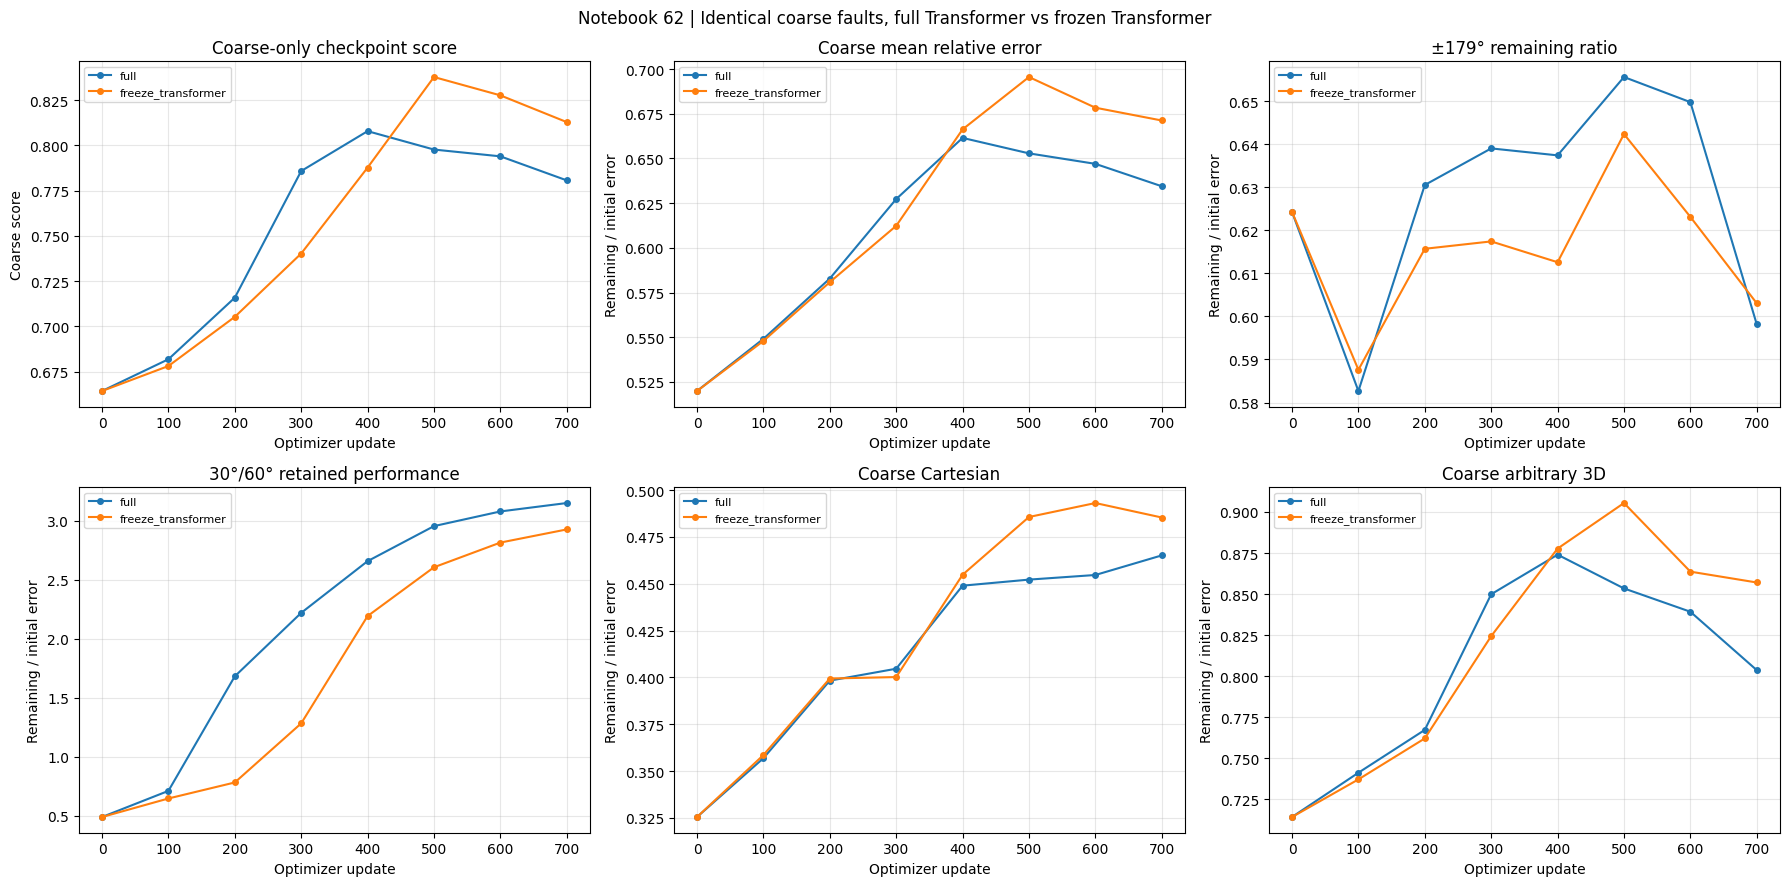

,mode,score,coarse_mean,cartesian_mean,arbitrary_mean,near_pi,fine_mean,zero_drift_deg,transformer_delta
7,full,0.7807,0.6344,0.4652,0.8037,0.5982,3.1515,37.1438,0.5037
15,freeze_transformer,0.8129,0.6712,0.4854,0.8571,0.6030,2.9276,1.7978,0.0000


,mode,best_step,best_coarse_score,transformer_should_be_frozen
0,full,0,0.664241,False
1,freeze_transformer,0,0.664241,True


Final coarse ratio per sensor and axis: full


axis_label,3D,X,Y,Z
fault_key,,,,
imu,0.715,0.879,0.364,0.52
lidar,0.855,0.447,0.359,0.38
lidar_right,0.841,0.474,0.373,0.39


Final coarse ratio per sensor and axis: freeze_transformer


axis_label,3D,X,Y,Z
fault_key,,,,
imu,0.859,0.833,0.379,0.691
lidar,0.867,0.482,0.369,0.372
lidar_right,0.846,0.498,0.347,0.399


In [25]:
if STOCHASTIC_HISTORY_62:
    history_62 = pd.DataFrame(STOCHASTIC_HISTORY_62)
    fig, axes = plt.subplots(2, 3, figsize=(18, 9))
    metrics = [('score', 'Coarse-only checkpoint score'), ('coarse_mean', 'Coarse mean relative error'), ('near_pi', '±179° remaining ratio'), ('fine_mean', '30°/60° retained performance'), ('cartesian_mean', 'Coarse Cartesian'), ('arbitrary_mean', 'Coarse arbitrary 3D')]
    for ax, (field, title) in zip(axes.ravel(), metrics):
        for mode, group in history_62.groupby('mode', sort=False):
            ax.plot(group.step, group[field], '-o', markersize=4, label=mode)
        ax.set(xlabel='Optimizer update', ylabel='Remaining / initial error' if field != 'score' else 'Coarse score', title=title)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    fig.suptitle('Notebook 62 | Identical coarse faults, full Transformer vs frozen Transformer')
    fig.tight_layout()
    fig.savefig(stochastic_dir / 'stochastic_mode_comparison.png', dpi=170)
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)

    display(history_62.groupby('mode', sort=False).tail(1)[['mode','score','coarse_mean','cartesian_mean','arbitrary_mean','near_pi','fine_mean','zero_drift_deg','transformer_delta']].round(4))
    selected_best_rows = []
    for mode in STOCHASTIC_MODES:
        raw = torch.load(STOCHASTIC_BEST_PATHS[mode], map_location='cpu', weights_only=True)
        selected_best_rows.append(dict(mode=mode, best_step=raw['step'], best_coarse_score=raw['score'], transformer_should_be_frozen=(mode == 'freeze_transformer')))
    display(pd.DataFrame(selected_best_rows))

    # Coarse per-sensor / per-axis results at the FINAL step, not only averaged scores.
    pairs_62 = pd.DataFrame(STOCHASTIC_PAIR_HISTORY_62)
    for mode in STOCHASTIC_MODES:
        latest = pairs_62[(pairs_62['mode'] == mode) & (pairs_62['step'] == STOCHASTIC_STEPS)]
        print('Final coarse ratio per sensor and axis:', mode)
        display(latest.assign(axis_label=lambda x: np.where(x.axis_type == 'cartesian', x.axis, '3D')).groupby(['fault_key', 'axis_label']).ratio.mean().unstack('axis_label').round(3))

,checkpoint,score,cartesian_mean,arbitrary_mean,coarse_mean,worst_pair,near_pi,fine_mean,medium_mean,zero_drift_deg
0,002.27 original,0.798,0.602,0.654,0.628,1.008,0.747,0.324,NaN,1.181
1,002.28 coarse,0.905,0.882,0.697,0.789,1.005,0.614,1.408,NaN,1.486
2,002.30 single-axis,0.664,0.325,0.714,0.520,0.848,0.624,0.488,NaN,1.165


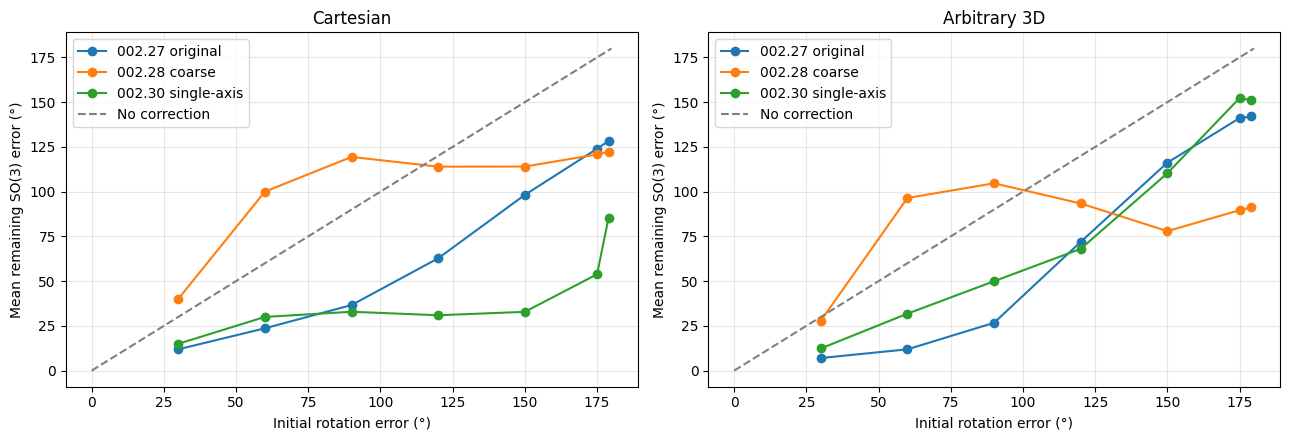

In [27]:

# Compare historical checkpoints on identical Notebook 62 probe cases.
# No training or optimizer changes.

checkpoint_paths = {
    "002.27 original": SOURCE_227_PATH,
    "002.28 coarse": ROOT / "runs" / "kaist_pooled_calibration_6d_002.28_coarse_120_179_finetune" / "last.pt",
    "002.30 single-axis": SOURCE_230_PATH,
}

comparison_rows = []
comparison_cases = []

for label, path in checkpoint_paths.items():
    if not path.is_file():
        raise FileNotFoundError(path)

    candidate = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=DTYPE)

    load_training_checkpoint(
        path,
        model=candidate,
        map_location=DEVICE,
        restore_rng_state=False,
    )

    candidate.eval()

    frame = evaluate_probe_bank(
        candidate,
        stochastic_probes,
        name=label,
    )

    metrics, _ = coarse_probe_metrics_62(frame)
    comparison_rows.append({"checkpoint": label, **metrics})
    comparison_cases.append(frame)

    del candidate

checkpoint_comparison_df = pd.DataFrame(comparison_rows)
checkpoint_comparison_cases = pd.concat(comparison_cases, ignore_index=True)

display(checkpoint_comparison_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for label, group in checkpoint_comparison_cases.groupby("model"):
    selected = group[
        (group.angle_deg > 0)
        & group.axis_type.isin(("cartesian", "arbitrary"))
    ]

    for ax, family in zip(axes, ("cartesian", "arbitrary")):
        summary = (
            selected[selected.axis_type == family]
            .groupby("angle_deg", as_index=False)
            .agg(residual_deg=("after_deg", "mean"))
        )

        ax.plot(
            summary.angle_deg,
            summary.residual_deg,
            "-o",
            label=label,
        )

for ax, family in zip(axes, ("Cartesian", "Arbitrary 3D")):
    ax.plot([0, 180], [0, 180], "--", color="gray", label="No correction")
    ax.set(
        title=family,
        xlabel="Initial rotation error (°)",
        ylabel="Mean remaining SO(3) error (°)",
    )
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


### Independent confirmation of stochastic-best checkpoints

The curves above select each stochastic-best checkpoint on a small fixed validation bank. Before choosing a full run, evaluate the **two best checkpoints and source model on a larger, separately seeded validation bank** with identical Cartesian/3D faults. This also reports how much each module changed relative to 002.30. This confirmation is still **validation**, not the untouched test set.

Independent confirmation (lower is better):


,model,score,cartesian_mean,arbitrary_mean,coarse_mean,worst_pair,near_pi,fine_mean,medium_mean,zero_drift_deg
0,2.30 source,0.758,0.3767,0.7769,0.5768,1.0193,0.7058,0.5135,NaN,1.1975
1,full,0.758,0.3767,0.7769,0.5768,1.0193,0.7058,0.5135,NaN,1.1975
2,freeze_transformer,0.758,0.3767,0.7769,0.5768,1.0193,0.7058,0.5135,NaN,1.1975


Relative parameter change from the 002.30 source:


model,2.30 source,freeze_transformer,full
block,,,
head_6d,0.0,0.0,0.0
mlp_body,0.0,0.0,0.0
pooler,0.0,0.0,0.0
transformer_encoder,0.0,0.0,0.0


Coarse residual ratio by sensor/axis:


axis_label                         3D      X      Y      Z
model              fault_key                              
2.30 source        imu          0.663  0.195  0.083  0.628
                   lidar        0.835  0.688  0.233  0.318
                   lidar_right  0.832  0.699  0.245  0.302
freeze_transformer imu          0.663  0.195  0.083  0.628
                   lidar        0.835  0.688  0.233  0.318
                   lidar_right  0.832  0.699  0.245  0.302
full               imu          0.663  0.195  0.083  0.628
                   lidar        0.835  0.688  0.233  0.318
                   lidar_right  0.832  0.699  0.245  0.302

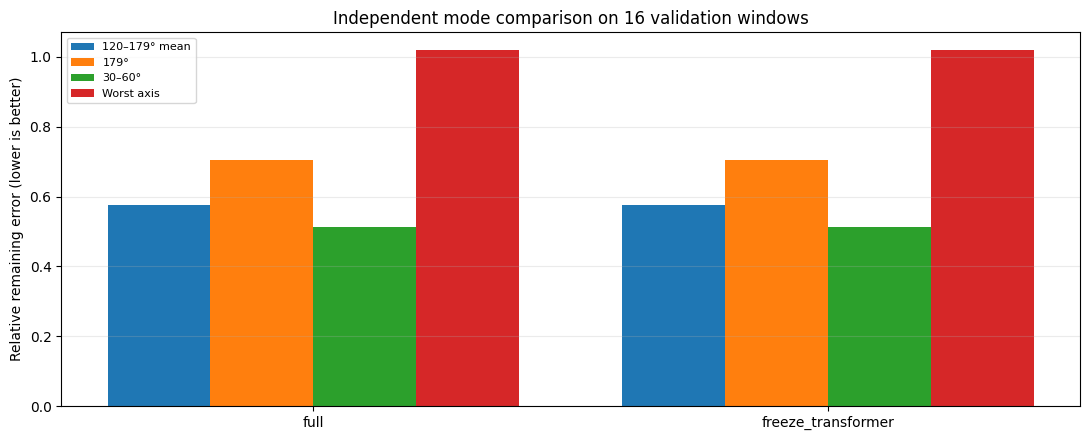

In [28]:
STOCHASTIC_CONFIRM_WINDOWS = 16
STOCHASTIC_CONFIRM_DIRECTIONS = 3
confirm_paths = {mode: path for mode, path in STOCHASTIC_BEST_PATHS.items() if path.is_file()}
if len(confirm_paths) == len(STOCHASTIC_MODES):
    confirm_bank = build_probe_bank(val_dataset, n_windows=STOCHASTIC_CONFIRM_WINDOWS, batch_size=8, seed=PROBE_SEED + 62_999, angles=PROBE_ANGLES_DEG, n_sphere_directions=STOCHASTIC_CONFIRM_DIRECTIONS)
    source_confirm = load_62_model().eval().requires_grad_(False)
    confirm_models = {'2.30 source': source_confirm}
    for mode, path in confirm_paths.items():
        candidate = load_62_model()
        raw = torch.load(path, map_location='cpu', weights_only=True)
        assert raw['mode'] == mode
        candidate.load_state_dict(raw['model_state_dict'], strict=True)
        confirm_models[mode] = candidate.eval().requires_grad_(False)
    confirm_scores, confirm_pairs, confirm_changes = [], [], []
    for name, candidate in confirm_models.items():
        frame = evaluate_probe_bank(candidate, confirm_bank, name=name)
        metrics, groups = coarse_probe_metrics_62(frame)
        confirm_scores.append(dict(model=name, **metrics))
        groups['model'] = name
        confirm_pairs.extend(groups.to_dict('records'))
        for block in ('transformer_encoder', 'pooler', 'mlp_body', 'head_6d'):
            src_module, dst_module = getattr(source_confirm, block), getattr(candidate, block)
            numerator = sum(float((a - b).square().sum()) for a, b in zip(src_module.parameters(), dst_module.parameters()))
            denominator = sum(float(b.square().sum()) for b in src_module.parameters())
            confirm_changes.append(dict(model=name, block=block, delta_L2=math.sqrt(numerator), relative_L2=math.sqrt(numerator / max(denominator, 1e-20))))
    confirm_df = pd.DataFrame(confirm_scores)
    confirm_pair_df = pd.DataFrame(confirm_pairs)
    confirm_change_df = pd.DataFrame(confirm_changes)
    confirm_df.to_csv(stochastic_dir / 'confirmation_scores.csv', index=False)
    confirm_pair_df.to_csv(stochastic_dir / 'confirmation_sensor_axis.csv', index=False)
    confirm_change_df.to_csv(stochastic_dir / 'confirmation_parameter_deltas.csv', index=False)
    print('Independent confirmation (lower is better):')
    display(confirm_df.round(4))
    print('Relative parameter change from the 002.30 source:')
    display(confirm_change_df.pivot(index='block', columns='model', values='relative_L2').round(5))
    confirm_pair_df['axis_label'] = np.where(confirm_pair_df.axis_type == 'cartesian', confirm_pair_df.axis, '3D')
    print('Coarse residual ratio by sensor/axis:')
    display(confirm_pair_df.groupby(['model','fault_key','axis_label']).ratio.mean().unstack('axis_label').round(3))
    fig, ax = plt.subplots(figsize=(11, 4.5))
    select = confirm_df[confirm_df.model.isin(STOCHASTIC_MODES)]
    x = np.arange(len(select))
    width = 0.20
    for offset, field, label in [(-1.5,'coarse_mean','120–179° mean'),(-0.5,'near_pi','179°'),(0.5,'fine_mean','30–60°'),(1.5,'worst_pair','Worst axis')]:
        ax.bar(x + offset * width, select[field], width=width, label=label)
    ax.set_xticks(x, select.model)
    ax.set(ylabel='Relative remaining error (lower is better)', title='Independent mode comparison on 16 validation windows')
    ax.grid(axis='y', alpha=0.25)
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(stochastic_dir / 'confirmation_mode_comparison.png', dpi=180)
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)
    del confirm_models, source_confirm
else:
    print('Independent stochastic confirmation skipped. Run both modes first or restore their best.pt files.')

### How to choose the full mode

Prefer **`freeze_transformer`** if its matched coarse validation is comparable to full (including individual LiDAR axes and ±179°), and its Transformer delta remains exactly zero. This supports downstream specialization using one shared pretrained Transformer. If `full` clearly wins on coarse 3D or LiDAR X, the encoder is part of the bottleneck.

This is a *coarse specialist*, so degradation at 30° is expected. In a later two-branch system a separate fine branch and a **measurable switch/confidence rule** would be required. We cannot select the branch from unknown ground-truth initial error at inference.

## 8. Full coarse training: choose a mode and resume from its own `last.pt`

In [ ]:
# FULL_TRAIN_MODE is selected in Settings, not inferred from one noisy score.
FULL_RUN_DIR = RUN_DIR / f'full_{FULL_TRAIN_MODE}'
BEST_CHECKPOINT_PATH = FULL_RUN_DIR / 'best.pt'
LAST_CHECKPOINT_PATH = FULL_RUN_DIR / 'last.pt'
HISTORY_PATH = FULL_RUN_DIR / 'history.csv'
PAIR_HISTORY_PATH = FULL_RUN_DIR / 'coarse_pair_history.csv'
FULL_RUN_DIR.mkdir(parents=True, exist_ok=True)

full_init_path = SOURCE_230_PATH if FULL_INIT_MODE == 'source' else STOCHASTIC_BEST_PATHS[FULL_TRAIN_MODE]
if RUN_FULL_TRAINING and not full_init_path.is_file():
    raise FileNotFoundError(full_init_path)

# Recreate the model and optimizer in the selected mode. No module is reinitialized by freezing.
model = set_62_train_mode(load_62_model(), FULL_TRAIN_MODE)
print('Full mode:', train_mode_checks_62(model, FULL_TRAIN_MODE))
optimizer = torch.optim.AdamW(trainable_parameter_groups_62(model, transformer_lr=TRANSFORMER_LR, other_lr=HEAD_MLP_LR), weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=LR_REDUCE_FACTOR, patience=LR_PATIENCE_PROBES)
train_generator = augmentation_generator(TRAIN_AUG_SEED + 62_100)
start_epoch, global_step, best_score, best_epoch = 0, 0, float('inf'), 0
history, pair_history = [], []
full_probe_bank = build_probe_bank(val_dataset, n_windows=FULL_PROBE_WINDOWS, batch_size=FULL_PROBE_BATCH_SIZE, seed=PROBE_SEED, angles=PROBE_ANGLES_DEG, n_sphere_directions=FULL_PROBE_3D_DIRECTIONS)

# Immutable settings only. FULL_TARGET_EPOCHS is intentionally excluded for resumption.
config_62 = dict(
    source_checkpoint=str(SOURCE_230_PATH), initialization=str(full_init_path), mode=FULL_TRAIN_MODE,
    calibration_keys=tuple(CALIBRATION_KEYS), train_names=tuple(TRAIN_NAMES), val_names=tuple(VAL_NAMES),
    coarse_bounds=(COARSE_ROTATION_MIN_DEG, COARSE_ROTATION_MAX_DEG),
    cartesian_probability=COARSE_CARTESIAN_PROBABILITY, identity_probability=COARSE_IDENTITY_PROBABILITY,
    true_frames_randomized=RANDOMIZE_TRUE_SENSOR_FRAMES, true_rotation_max_rad=TRUE_CALIBRATION_ROTATION_MAX_RAD,
    loss_weights=asdict(LOSS_WEIGHTS), active_weight=ACTIVE_ROTATION_SUPERVISION_WEIGHT,
    batch_size=TRAIN_BATCH_SIZE, grad_accumulation=GRADIENT_ACCUMULATION_STEPS,
    transformer_lr=TRANSFORMER_LR, downstream_lr=HEAD_MLP_LR, weight_decay=WEIGHT_DECAY,
    gradient_clip=GRADIENT_CLIP_NORM, scheduler_factor=LR_REDUCE_FACTOR, scheduler_patience=LR_PATIENCE_PROBES,
    probe_angles=tuple(PROBE_ANGLES_DEG), probe_seed=PROBE_SEED,
    probe_windows=FULL_PROBE_WINDOWS, probe_directions=FULL_PROBE_3D_DIRECTIONS,
    probe_every=PROBE_EVERY_EPOCHS, score_weight=PROBE_CARTESIAN_SCORE_WEIGHT,
    worst_weight=WORST_PAIR_WEIGHT, near_pi_weight=NEAR_PI_WEIGHT, zero_weight=ZERO_DRIFT_WEIGHT,
)


def save_62_checkpoint(path, epoch, metrics):
    save_training_checkpoint(
        path, model=model, optimizer=optimizer, scheduler=scheduler, epoch=epoch,
        global_step=global_step, metrics=metrics,
        generators={'train_shuffle': train_shuffle_generator, 'train_aug': train_generator},
        extra_state={'config_62': config_62, 'best_score': best_score, 'best_epoch': best_epoch},
    )

if RUN_FULL_TRAINING:
    if RESUME_FULL_TRAINING:
        if not LAST_CHECKPOINT_PATH.is_file():
            raise FileNotFoundError(f'Missing last.pt for full-mode resume: {LAST_CHECKPOINT_PATH}')
        raw = torch.load(LAST_CHECKPOINT_PATH, map_location='cpu', weights_only=False)  # Trusted local training checkpoint only.
        saved_config = (raw.get('extra_state') or {}).get('config_62')
        if saved_config != config_62:
            diffs = {key: (None if saved_config is None else saved_config.get(key), config_62.get(key)) for key in set(saved_config or {}) | set(config_62) if (saved_config or {}).get(key) != config_62.get(key)}
            raise ValueError(f'Resume configuration differs. Use a new run directory: {diffs}')
        best_score, best_epoch = float(raw['extra_state']['best_score']), int(raw['extra_state']['best_epoch'])
        del raw
        loaded = load_training_checkpoint(
            LAST_CHECKPOINT_PATH, model=model, optimizer=optimizer, scheduler=scheduler,
            generators={'train_shuffle': train_shuffle_generator, 'train_aug': train_generator},
            map_location=DEVICE, restore_rng_state=True,
        )
        start_epoch, global_step = int(loaded['epoch']), int(loaded['global_step'])
        # Frozen mode must stay frozen even after state_dict restoration.
        train_mode_checks_62(model, FULL_TRAIN_MODE)
        if not optimizer.state:
            raise RuntimeError('AdamW moments not restored')
        if not HISTORY_PATH.is_file():
            raise FileNotFoundError(f'History required to resume: {HISTORY_PATH}')
        frame = pd.read_csv(HISTORY_PATH)
        if frame.empty or int(frame.epoch.iloc[-1]) != start_epoch:
            raise RuntimeError('Checkpoint epoch does not match training history')
        history = frame.to_dict('records')
        if PAIR_HISTORY_PATH.is_file():
            pair_history = pd.read_csv(PAIR_HISTORY_PATH).to_dict('records')
        if FULL_TARGET_EPOCHS <= start_epoch:
            raise ValueError('FULL_TARGET_EPOCHS must exceed the number of already completed epochs')
        print('Resumed:', FULL_TRAIN_MODE, 'completed epochs:', start_epoch, 'AdamW entries:', len(optimizer.state), 'target:', FULL_TARGET_EPOCHS)
    else:
        if any(path.is_file() for path in (BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH, HISTORY_PATH)):
            raise FileExistsError(f'Run already exists: {FULL_RUN_DIR}; resume explicitly or change RUN_NAME')
        if FULL_INIT_MODE == 'stochastic_best':
            raw = torch.load(full_init_path, map_location='cpu', weights_only=True)
            assert raw['mode'] == FULL_TRAIN_MODE
            model.load_state_dict(raw['model_state_dict'], strict=True)
            del raw
        # For a new run, ALL optimizer moments are fresh even when loading stochastic-best weights.
        baseline = evaluate_probe_bank(model, full_probe_bank, name='initial_full')
        initial_metrics, _ = coarse_probe_metrics_62(baseline)
        best_score = initial_metrics['score']
        save_62_checkpoint(BEST_CHECKPOINT_PATH, 0, dict(initial=True, **initial_metrics))
        print('New coarse specialist:', FULL_TRAIN_MODE, 'initial coarse score:', best_score)
else:
    print('Full training disabled. Checkpoints are only written when explicitly enabled.')

## 9. Unchanged supervised objective, coarse-only training epochs

In [ ]:
def run_62_epoch(loader, *, training, generator, max_batches=None):
    model.train(training)
    if training and FULL_TRAIN_MODE == 'freeze_transformer':
        model.transformer_encoder.eval()
    sums, counts = defaultdict(float), defaultdict(float)
    n_samples, optimizer_updates = 0, 0
    pending_samples, pending_microbatches = 0, 0
    if training:
        optimizer.zero_grad(set_to_none=True)

    def flush():
        nonlocal pending_samples, pending_microbatches, optimizer_updates
        if not pending_samples:
            return
        for param in model.parameters():
            if param.grad is not None:
                param.grad.div_(pending_samples)
        torch.nn.utils.clip_grad_norm_((p for p in model.parameters() if p.requires_grad), GRADIENT_CLIP_NORM)
        optimizer.step()
        optimizer.zero_grad(set_to_none=True)
        pending_samples = pending_microbatches = 0
        optimizer_updates += 1

    with (torch.enable_grad() if training else torch.no_grad()):
        for batch_id, cpu_batch in enumerate(loader):
            if max_batches is not None and batch_id >= max_batches:
                break
            base = window_batch_to(cpu_batch, DEVICE, dtype=DTYPE)
            batch = sample_coarse_window_62(base, generator=generator)
            output = model_predictions(batch)
            loss, metrics = compute_6d_objective(batch, output)
            if not bool(torch.isfinite(loss)):
                raise FloatingPointError(f'Nonfinite coarse training/validation loss at batch {batch_id}')
            n = next(iter(batch.current_calibration.values())).transform.shape[0]
            if training:
                (loss * n).backward()
                pending_samples += n
                pending_microbatches += 1
                if pending_microbatches >= GRADIENT_ACCUMULATION_STEPS:
                    flush()
            for name, value in metrics.items():
                if name != 'active_rotation_count':
                    sums[name] += float(value) * n
                    counts[name] += n
            n_samples += n
        if training:
            flush()
    if n_samples == 0:
        raise RuntimeError('No samples were processed')
    return {**{name: sums[name] / counts[name] for name in sums}, 'samples': n_samples, 'optimizer_updates': optimizer_updates}

if RUN_FULL_TRAINING:
    for epoch in range(start_epoch, FULL_TARGET_EPOCHS):
        train_shuffle_generator.manual_seed(RANDOM_SEED + 62_001 + epoch)
        train_result = run_62_epoch(train_loader, training=True, generator=train_generator, max_batches=MAX_TRAIN_BATCHES_PER_EPOCH)
        val_result = run_62_epoch(val_loader, training=False, generator=augmentation_generator(VAL_AUG_SEED + 62_100), max_batches=MAX_VAL_BATCHES_PER_EPOCH)
        global_step += train_result['optimizer_updates']
        record = dict(epoch=epoch + 1, global_step=global_step, mode=FULL_TRAIN_MODE, train_loss=train_result['loss_total'], val_loss=val_result['loss_total'], train_active_deg=train_result['active_rotation_error_deg'], val_active_deg=val_result['active_rotation_error_deg'])
        improved = False
        if (epoch + 1) % PROBE_EVERY_EPOCHS == 0:
            frame = evaluate_probe_bank(model, full_probe_bank, name=FULL_TRAIN_MODE)
            scores, pairs = coarse_probe_metrics_62(frame)
            scheduler.step(scores['score'])
            record.update({f'probe_{key}': value for key, value in scores.items()})
            pairs['epoch'], pairs['global_step'], pairs['mode'] = epoch + 1, global_step, FULL_TRAIN_MODE
            pair_history.extend(pairs.to_dict('records'))
            if scores['score'] < best_score:
                best_score, best_epoch = scores['score'], epoch + 1
                improved = True
        record.update(transformer_lr=optimizer.param_groups[0]['lr'], downstream_lr=optimizer.param_groups[1]['lr'])
        history.append(record)
        if improved:
            save_62_checkpoint(BEST_CHECKPOINT_PATH, epoch + 1, record)
        pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
        if pair_history:
            pd.DataFrame(pair_history).to_csv(PAIR_HISTORY_PATH, index=False)
        save_62_checkpoint(LAST_CHECKPOINT_PATH, epoch + 1, record)
        if FULL_TRAIN_MODE == 'freeze_transformer':
            # Compare to an untouched reference, never silently update the encoder.
            reference = load_62_model().eval().requires_grad_(False) if epoch == start_epoch or (epoch + 1) == FULL_TARGET_EPOCHS else None
            if reference is not None:
                assert transformer_weight_change_62(model, reference) == 0.0
                del reference
        score_str = f'coarse={record["probe_coarse_mean"]:.3f} 3D={record["probe_arbitrary_mean"]:.3f} fine={record["probe_fine_mean"]:.3f} score={record["probe_score"]:.4f}' if 'probe_score' in record else 'probe skipped'
        print(f'Epoch {epoch+1:3d}/{FULL_TARGET_EPOCHS} ({FULL_TRAIN_MODE}) train={record["train_loss"]:.4f} val={record["val_loss"]:.4f} | {score_str}' + (' BEST' if improved else ''), flush=True)
    print('Finished coarse specialist. Best epoch:', best_epoch, 'best coarse score:', best_score)
else:
    print('Full training was not requested; model weights are unchanged.')

In [ ]:
if HISTORY_PATH.is_file():
    trace = pd.read_csv(HISTORY_PATH)
    if 'probe_score' in trace:
        fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
        axes[0].plot(trace.epoch, trace.train_loss, label='Train'); axes[0].plot(trace.epoch, trace.val_loss, label='Val')
        for field, label in [('probe_coarse_mean', 'Coarse'), ('probe_fine_mean', 'Fine diagnostics'), ('probe_near_pi', '179°')]:
            axes[1].plot(trace.epoch, trace[field], '-o', markersize=3, label=label)
        axes[2].plot(trace.epoch, trace.probe_score, '-o', markersize=3, label='Coarse checkpoint score')
        for ax in axes:
            ax.grid(alpha=0.3); ax.set(xlabel='Epoch'); ax.legend()
        axes[0].set(title='6D training objective', ylabel='Loss')
        axes[1].set(title='Performance vs angle regime', ylabel='Remaining / initial error')
        axes[2].set(title='Checkpoint selection', ylabel='Score')
        fig.tight_layout()
        fig.savefig(FULL_RUN_DIR / 'training_and_coarse_probes.png', dpi=170)
        if SHOW_PLOTS:
            plt.show()
        else:
            plt.close(fig)
else:
    print('No full-run history yet.')

## 10. Post-training matched one-step comparison

In [ ]:
EVAL_DIR = FULL_RUN_DIR / 'plots' / 'post_training_comparison'
if RUN_POST_EVAL:
    if not BEST_CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(f'Train the full specialist first: {BEST_CHECKPOINT_PATH}')
    EVAL_DIR.mkdir(parents=True, exist_ok=True)
    def load_evaluation_model_62(path):
        candidate = PooledCalibration6DModel(model_config).to(device=DEVICE, dtype=DTYPE)
        if path in STOCHASTIC_BEST_PATHS.values():
            raw = torch.load(path, map_location='cpu', weights_only=True)
            candidate.load_state_dict(raw['model_state_dict'], strict=True)
        else:
            load_training_checkpoint(path, model=candidate, map_location=DEVICE, restore_rng_state=False)
        return candidate.eval().requires_grad_(False)
    eval_models_62 = {'2.30 source': load_evaluation_model_62(SOURCE_230_PATH), f'62 {FULL_TRAIN_MODE} best': load_evaluation_model_62(BEST_CHECKPOINT_PATH)}
    if EVAL_INCLUDE_STOCHASTIC_MODELS:
        for mode, path in STOCHASTIC_BEST_PATHS.items():
            if path.is_file():
                eval_models_62[f'stochastic {mode}'] = load_evaluation_model_62(path)
    evaluation_probes_62 = build_probe_bank(val_dataset, n_windows=EVAL_WINDOWS, batch_size=EVAL_BATCH_SIZE, seed=PROBE_SEED + 62_620, angles=PROBE_ANGLES_DEG, n_sphere_directions=EVAL_3D_DIRECTIONS)
    all_frames = []
    for name, candidate in eval_models_62.items():
        print('One-step:', name, flush=True)
        all_frames.append(evaluate_probe_bank(candidate, evaluation_probes_62, name=name))
    eval_one_62 = pd.concat(all_frames, ignore_index=True)
    eval_one_62.to_csv(EVAL_DIR / 'one_step_cases.csv', index=False)
    eval_summary_62 = []
    for name, frame in eval_one_62.groupby('model', sort=False):
        metrics, groups = coarse_probe_metrics_62(frame)
        eval_summary_62.append(dict(model=name, **metrics))
    display(pd.DataFrame(eval_summary_62).round(3))
    eval_one_62['axis_group'] = np.where(eval_one_62.axis_type == 'cartesian', eval_one_62.axis, np.where(eval_one_62.axis_type == 'arbitrary', '3D', 'I'))
    summary = eval_one_62[eval_one_62.angle_deg > 0].groupby(['model','fault_key','axis_group','angle_deg'], as_index=False).agg(after_deg=('after_deg', 'mean'), ratio=('relative_remaining', 'mean'), axis_cosine=('axis_cosine','mean'))
    summary.to_csv(EVAL_DIR / 'one_step_per_sensor_axis_angle.csv', index=False)
else:
    print('Post-training comparison disabled. Set RUN_POST_EVAL=True after full training.')

In [ ]:
if RUN_POST_EVAL:
    for field, ylabel, title in [('after_deg','Mean remaining SO(3) error (°)','One-step residuals'), ('axis_cosine','Signed predicted/GT axis cosine','Direction alignment')]:
        fig, axes = plt.subplots(3, 4, figsize=(20, 12), sharex=True)
        for r, sensor in enumerate(CALIBRATION_KEYS):
            for col, family in enumerate(('X','Y','Z','3D')):
                ax = axes[r, col]
                data = summary[(summary.fault_key == sensor) & (summary.axis_group == family)]
                for name, group in data.groupby('model', sort=False):
                    ax.plot(group.angle_deg, group[field], '-o', markersize=3, label=name)
                if field == 'after_deg':
                    xx = np.array(PROBE_ANGLES_DEG[1:])
                    ax.plot(xx, xx, linestyle=':', color='gray', linewidth=1.1, label='No correction')
                else:
                    ax.axhline(0.0, linestyle=':', color='gray', linewidth=1)
                    ax.set_ylim(-1.05, 1.05)
                ax.set(title=f'{sensor} | {family}', xlabel='Initial error (°)', ylabel=ylabel)
                ax.grid(alpha=0.25)
        axes[0, 0].legend(fontsize=7)
        fig.suptitle(f'Notebook 62 | {title} | matched probes', fontsize=15)
        fig.tight_layout()
        fig.savefig(EVAL_DIR / f'{field}_all_sensor_axes.png', dpi=180)
        if SHOW_PLOTS:
            plt.show()
        else:
            plt.close(fig)

    coarse_179 = eval_one_62.loc[eval_one_62.angle_deg == 179].copy()
    coarse_179['axis_group'] = np.where(coarse_179.axis_type == 'cartesian', coarse_179.axis, '3D')
    print('179° residuals for all sensors and axis groups (deg):')
    display(coarse_179.groupby(['model','fault_key','axis_group']).after_deg.agg(['mean','median',lambda x: x.quantile(.9)]).round(2))

## 11. Optional 12-window chronological feedback rollouts

In [ ]:
@torch.inference_mode()
def evaluate_62_rollouts(models, *, sequences=EVAL_ROLLOUT_SEQUENCES, starts=EVAL_ROLLOUT_STARTS,
                                truths=EVAL_ROLLOUT_TRUTHS, steps=EVAL_ROLLOUT_STEPS, angles=EVAL_ROLLOUT_ANGLES,
                                sphere_directions=EVAL_ROLLOUT_3D_DIRECTIONS, seed=VAL_AUG_SEED + 6_220_303):
    """Independent model feedback, matched GT and per-window raw measurements; only faulted R updates."""
    direction_specs = [('cartesian', axis, tuple(np.eye(3)[j])) for j, axis in enumerate('XYZ')]
    direction_specs += [('arbitrary', f'U{j+1}', tuple(vec)) for j, vec in enumerate(fixed_sphere_directions(sphere_directions, seed + 123))]
    direction_specs += [('identity', 'I', (0., 0., 0.))]
    I = torch.eye(3, device=DEVICE, dtype=DTYPE)
    records = []
    for seq_id, sequence in enumerate(sequences):
        sequence_indices = np.asarray(val_dataset.window_indices_for_sequence(sequence), dtype=np.int64)
        last_start = len(sequence_indices) - steps
        if last_start < 0:
            raise ValueError(f'{sequence}: expected {steps} consecutive windows, found {len(sequence_indices)}')
        start_positions = np.unique(np.linspace(0, last_start, min(starts, last_start + 1)).round().astype(int))
        for start_id, start in enumerate(start_positions):
            window_indices = sequence_indices[start:start + steps]
            for truth_id in range(truths):
                truth_seed = seed + seq_id * 1_000_003 + start_id * 100_003 + truth_id * 1009
                physical_windows = []
                for index in window_indices:
                    base = window_batch_to(collate_windows([val_dataset[int(index)]]), DEVICE, dtype=DTYPE)
                    # Reset to the same seed for each window so GT is constant across time.
                    physical = physical_augmenter(base, generator=augmentation_generator(truth_seed)).augmented_window
                    physical_windows.append(physical)
                truth = physical_windows[0].current_calibration
                for physical in physical_windows[1:]:
                    for key in CALIBRATION_KEYS:
                        torch.testing.assert_close(physical.current_calibration[key].transform, truth[key].transform, atol=2e-5, rtol=2e-5)
                        torch.testing.assert_close(physical.current_calibration[key].time_offset, truth[key].time_offset, atol=2e-6, rtol=2e-6)
                for fault_key in CALIBRATION_KEYS:
                    for family, axis, direction in direction_specs:
                        direction_vec = torch.tensor(direction, device=DEVICE, dtype=DTYPE)
                        these_angles = (0.,) if family == 'identity' else tuple(a for a in angles if a > 0)
                        for initial_angle in these_angles:
                            for sign in ((0,) if initial_angle == 0 else (1, -1)):
                                xi = {key: torch.zeros(1, 6, device=DEVICE, dtype=DTYPE) for key in CALIBRATION_KEYS}
                                xi[fault_key][:, :3] = float(np.deg2rad(initial_angle)) * sign * direction_vec[None, :]
                                initial_states = apply_independent_prior_faults(truth, xi)
                                for model_label, candidate in models.items():
                                    states = {key: replace(state, transform=state.transform.clone(), time_offset=state.time_offset.clone()) for key, state in initial_states.items()}
                                    for step in range(steps + 1):
                                        prior_R = states[fault_key].transform[:, :3, :3]
                                        truth_R = truth[fault_key].transform[:, :3, :3]
                                        residual = float(rotation_geodesic_deg(prior_R, truth_R)[0])
                                        record = dict(model=model_label, sequence=sequence, start_index=int(window_indices[0]), truth_id=truth_id,
                                                      fault_key=fault_key, axis_type=family, axis=axis, axis_group=axis if family == 'cartesian' else ('3D' if family == 'arbitrary' else 'I'),
                                                      sign=int(sign), initial_angle_deg=float(initial_angle), signed_angle_deg=float(sign * initial_angle),
                                                      step=step, residual_deg=residual, predicted_step_deg=np.nan, axis_cosine=np.nan)
                                        if step < steps:
                                            input_window = clone_with_current_calibration(physical_windows[step], states)
                                            predicted_R = model_predictions(input_window, model_override=candidate).predictions[fault_key].delta_rotation
                                            desired_R = truth_R @ prior_R.transpose(-1, -2)
                                            record['predicted_step_deg'] = float(rotation_geodesic_deg(predicted_R, I.expand_as(predicted_R))[0])
                                            record['axis_cosine'] = float(rotation_axis_cosine(predicted_R, desired_R)[0])
                                            next_T = states[fault_key].transform.clone()
                                            next_T[:, :3, :3] = predicted_R @ prior_R
                                            states = dict(states)
                                            states[fault_key] = replace(states[fault_key], transform=next_T)
                                        records.append(record)
                print(f'Finished matched 12-window rollouts: {sequence}, start={int(window_indices[0])}, truth {truth_id + 1}/{truths}', flush=True)
    return pd.DataFrame.from_records(records)

In [ ]:
if RUN_POST_EVAL and EVAL_ROLLOUTS:
    rollout_df_62 = evaluate_62_rollouts(eval_models_62)
    rollout_df_62.to_csv(EVAL_DIR / 'rollout_cases.csv', index=False)
    final_62 = rollout_df_62.loc[rollout_df_62.step == EVAL_ROLLOUT_STEPS].copy()
    final_62['success10'] = final_62.residual_deg < 10
    final_62['success30'] = final_62.residual_deg < 30
    display(final_62.groupby(['model','fault_key','axis_group','initial_angle_deg']).agg(mean_deg=('residual_deg','mean'),median_deg=('residual_deg','median'),p90_deg=('residual_deg', lambda x: x.quantile(.90)), success10=('success10','mean'),success30=('success30','mean')).round(2))
    for sensor in CALIBRATION_KEYS:
        frame = rollout_df_62[(rollout_df_62.fault_key == sensor) & (rollout_df_62.initial_angle_deg.isin((150.0,179.0)))]
        if frame.empty:
            continue
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
        for ax, angle in zip(axes, (150.0, 179.0)):
            data = frame[frame.initial_angle_deg == angle]
            for name, group in data.groupby('model', sort=False):
                trend = group.groupby('step').residual_deg.mean()
                ax.plot(trend.index, trend.values, '-o', label=name)
            ax.set(title=f'{sensor}: initial ±{angle:.0f}°', xlabel='Correction step', ylabel='Mean remaining error (°)')
            ax.grid(alpha=.3)
        axes[0].legend(fontsize=7)
        fig.tight_layout()
        fig.savefig(EVAL_DIR / f'rollout_{sensor}.png', dpi=165)
        if SHOW_PLOTS:
            plt.show()
        else:
            plt.close(fig)
else:
    print('Rollouts disabled. Enable RUN_POST_EVAL and EVAL_ROLLOUTS after training.')

## 12. Interpretation and next step

- **Frozen ≈ full:** The `002.30` Transformer may already contain sufficient features for a coarse specialist. A later architecture can share the encoder and use separate fine/coarse poolers, MLPs and 6D heads. This result alone does **not** mean a second 6D head attached after the same *single shared MLP* is enough, since the pooler and MLP were trainable in the frozen mode.
- **Full ≫ frozen:** Coarse adaptation needs changes inside the Transformer. Inspect per-layer changes or test adapters/late-layer specialization before scaling the whole backbone.
- **Both fail, particularly on arbitrary 3D:** The fine/coarse parameter conflict is not the only limitation. Compare sensor-specific task errors and generalization on different physical windows.
- **Specialist succeeds at coarse and loses fine:** Expected for specialization. Later define an inference-time switch based on observable confidence or update consistency, not ground-truth error magnitude.

**Evaluation discipline:** the validation probe is used for checkpoint selection and experimental decisions. Do not tune against the untouched test sequences until the design is frozen.